# Practical Assignment 6: Implementation of Clustering Algorithms

**Subject:** Computational Intelligence

**Submitted By:** Shravani Birajdar

**PRN:** 202401070065

**Dataset:** Credit Card Customer Segmentation (CC GENERAL)

**Platform:** Google Colab

**Objective:**

To implement and compare different clustering algorithms on a real-world credit card customer dataset to identify meaningful customer segments and evaluate clustering performance using appropriate validation metrics.

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Upload dataset in Google Colab

from google.colab import files

uploaded = files.upload()

# Load dataset
df = pd.read_csv('CC GENERAL.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Saving CC GENERAL.csv to CC GENERAL.csv
Dataset loaded successfully!
Dataset Shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [3]:
# Dataset information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe().T)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nNumber of Unique Customers:", df['CUST_ID'].nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null 

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000



Missing Values:
CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

Duplicate Rows: 0

Number of Unique Customers: 8950


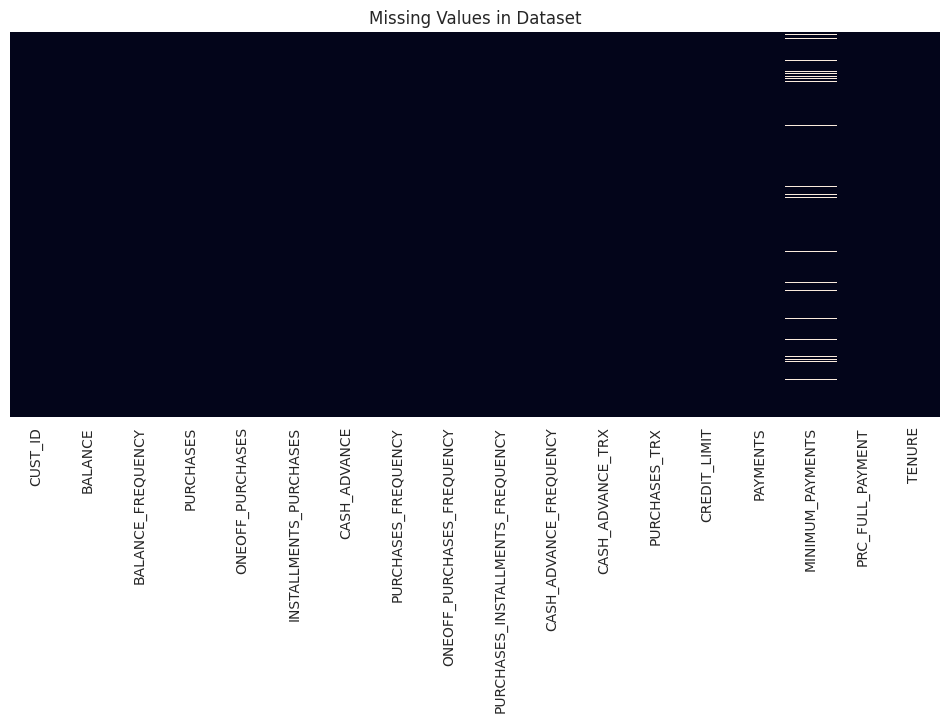

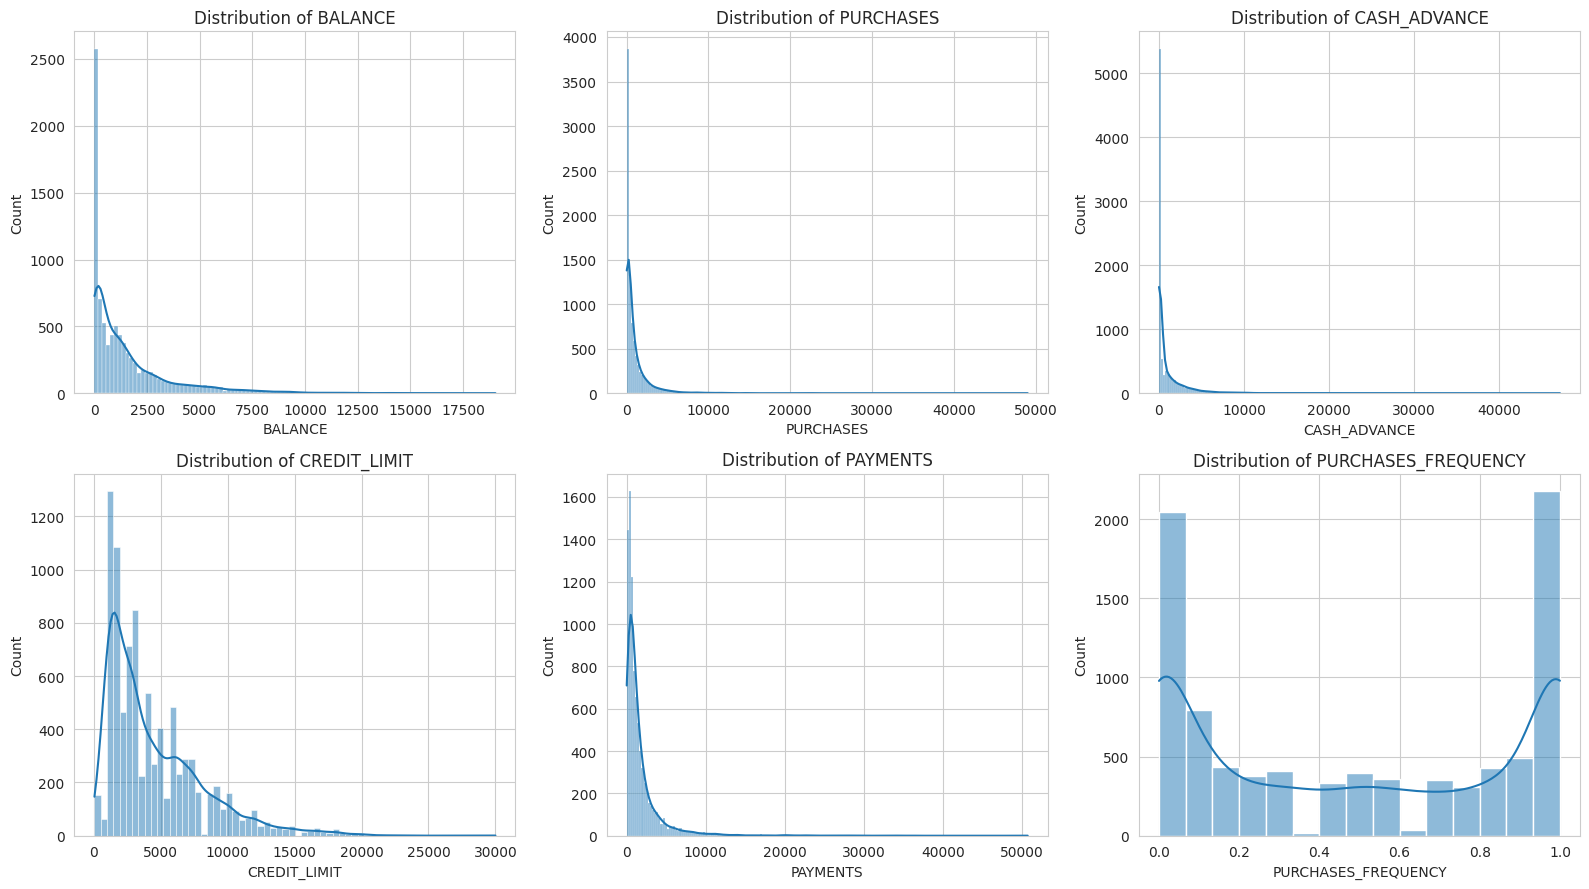

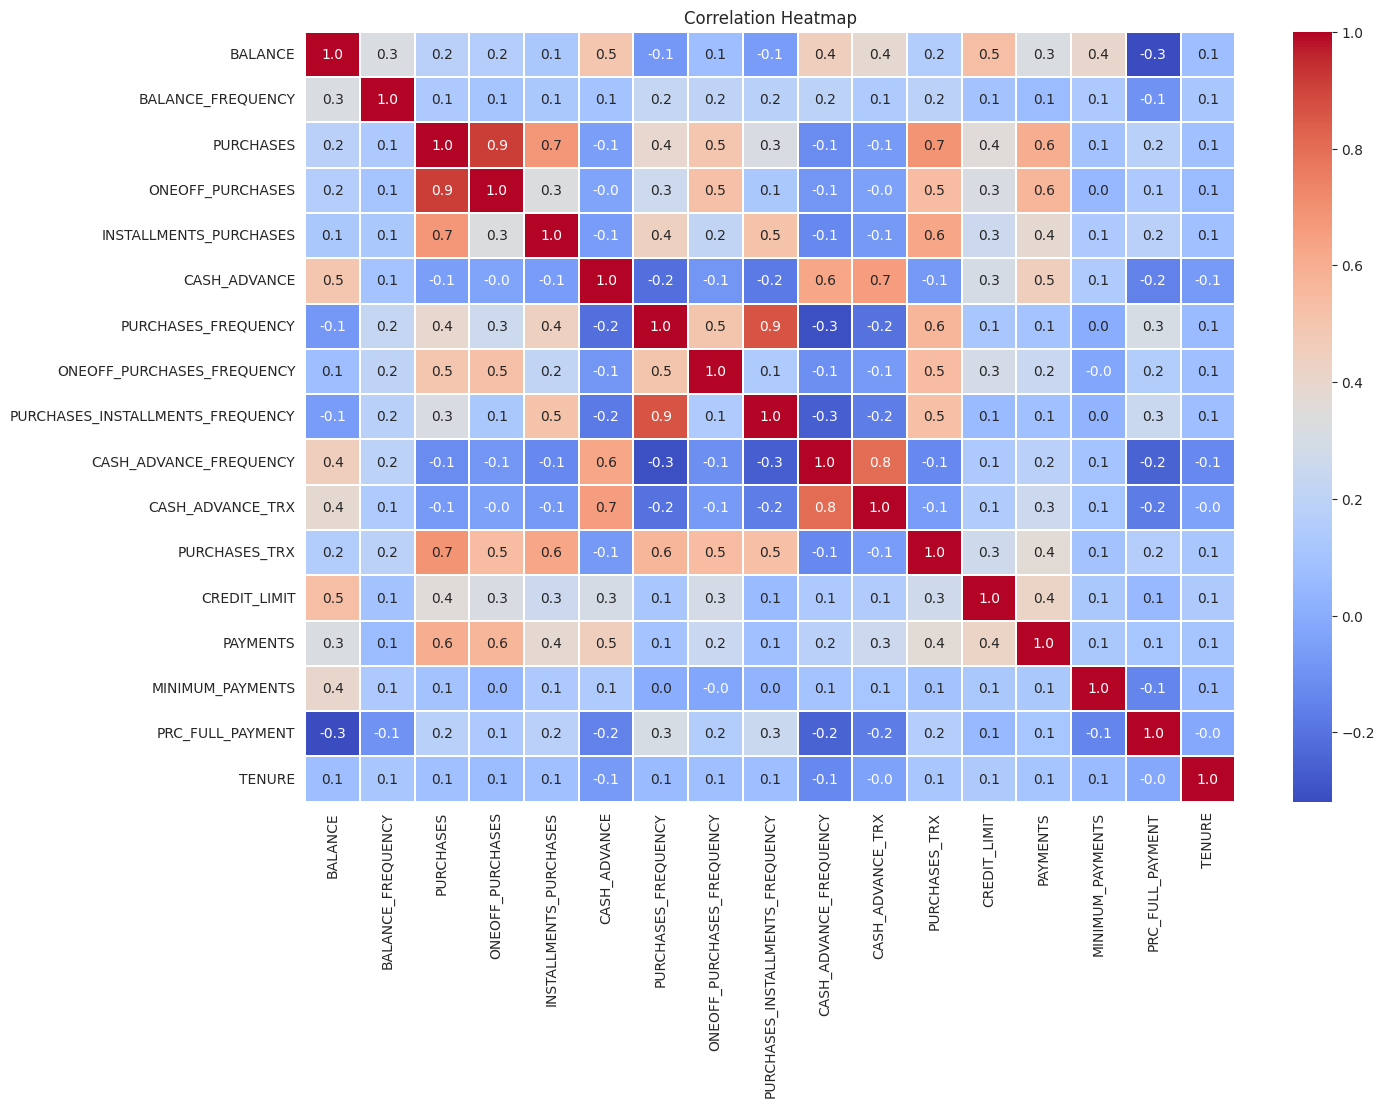

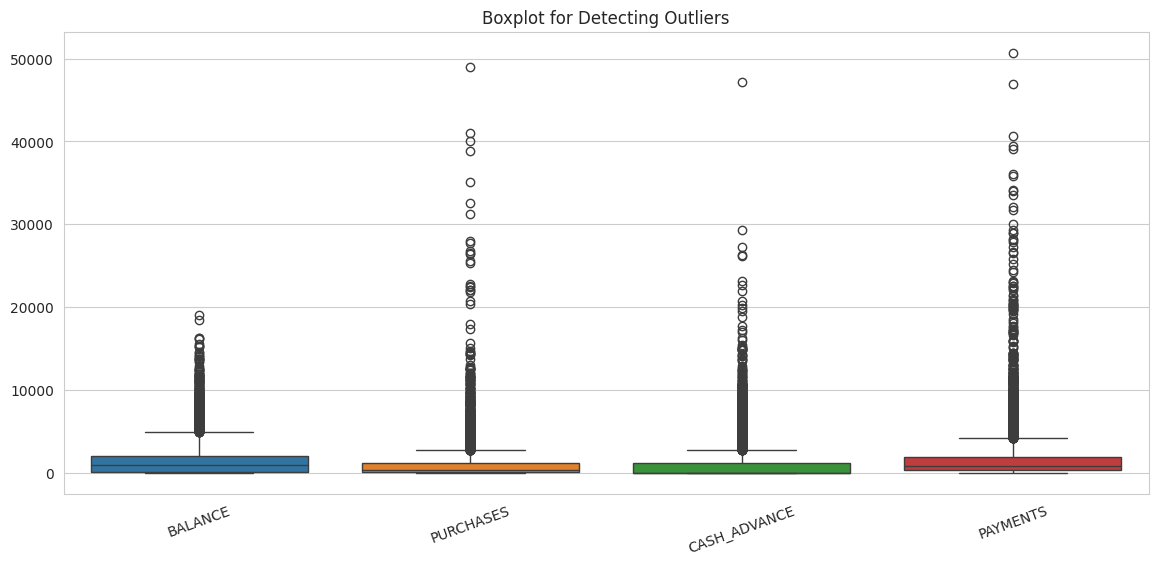

In [4]:
# 1. Missing values visualization

plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Dataset")
plt.show()


# 2. Distribution of important customer features

features = [
    'BALANCE',
    'PURCHASES',
    'CASH_ADVANCE',
    'CREDIT_LIMIT',
    'PAYMENTS',
    'PURCHASES_FREQUENCY'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for feature, ax in zip(features, axes.flatten()):
    sns.histplot(df[feature], kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()


# 3. Correlation heatmap

plt.figure(figsize=(15, 10))

correlation = df.drop(columns=['CUST_ID']).corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=True,
    fmt='.1f',
    linewidths=0.3
)

plt.title("Correlation Heatmap")
plt.show()


# 4. Outlier visualization

plt.figure(figsize=(14, 6))

sns.boxplot(data=df[['BALANCE', 'PURCHASES',
                     'CASH_ADVANCE', 'PAYMENTS']])

plt.title("Boxplot for Detecting Outliers")
plt.xticks(rotation=20)
plt.show()

In [5]:
# Create a copy of the dataset

data = df.copy()

# Remove customer ID
data.drop(columns=['CUST_ID'], inplace=True)

# Remove duplicate rows
data.drop_duplicates(inplace=True)

# Handle missing values using median imputation
imputer = SimpleImputer(strategy='median')

data_imputed = pd.DataFrame(
    imputer.fit_transform(data),
    columns=data.columns
)

# Apply log transformation to reduce skewness
data_log = np.log1p(data_imputed.clip(lower=0))

# Scale the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(data_log)

print("Preprocessing completed successfully!")

print("Original Dataset Shape:", df.shape)
print("Processed Dataset Shape:", X_scaled.shape)

print("Missing Values After Preprocessing:",
      np.isnan(X_scaled).sum())

print("\nProcessed Data Preview:")
display(pd.DataFrame(X_scaled, columns=data.columns).head())

Preprocessing completed successfully!
Original Dataset Shape: (8950, 18)
Processed Dataset Shape: (8950, 17)
Missing Values After Preprocessing: 0

Processed Data Preview:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-1.205218,-0.148757,-0.113532,-0.987090,0.394480,-0.930733,-0.746901,-0.732480,-0.674253,-0.724360,-0.810069,-0.579510,-1.447163,-0.824484,-0.829841,-0.556368,0.347262
1,0.948918,0.179616,-1.679855,-0.987090,-1.087454,1.528788,-1.302799,-0.732480,-0.958256,0.699592,0.784603,-1.379210,0.926060,1.065033,0.908184,0.391958,0.347262
2,0.824993,0.492710,0.600727,1.062022,-1.087454,-0.930733,1.196820,2.466762,-0.958256,-0.724360,-0.810069,0.487865,1.010229,-0.119300,0.450407,-0.556368,0.347262
3,0.624653,-0.857867,0.827499,1.265778,-1.087454,0.564372,-1.014151,-0.363042,-0.958256,-0.213583,-0.123281,-0.874655,1.010229,-4.161996,-0.144271,-0.556368,0.347262
4,0.271260,0.492710,-0.708481,-0.114307,-1.087454,-0.930733,-1.014151,-0.363042,-0.958256,-0.724360,-0.810069,-0.874655,-1.224909,-0.064979,-0.351833,-0.556368,0.347262


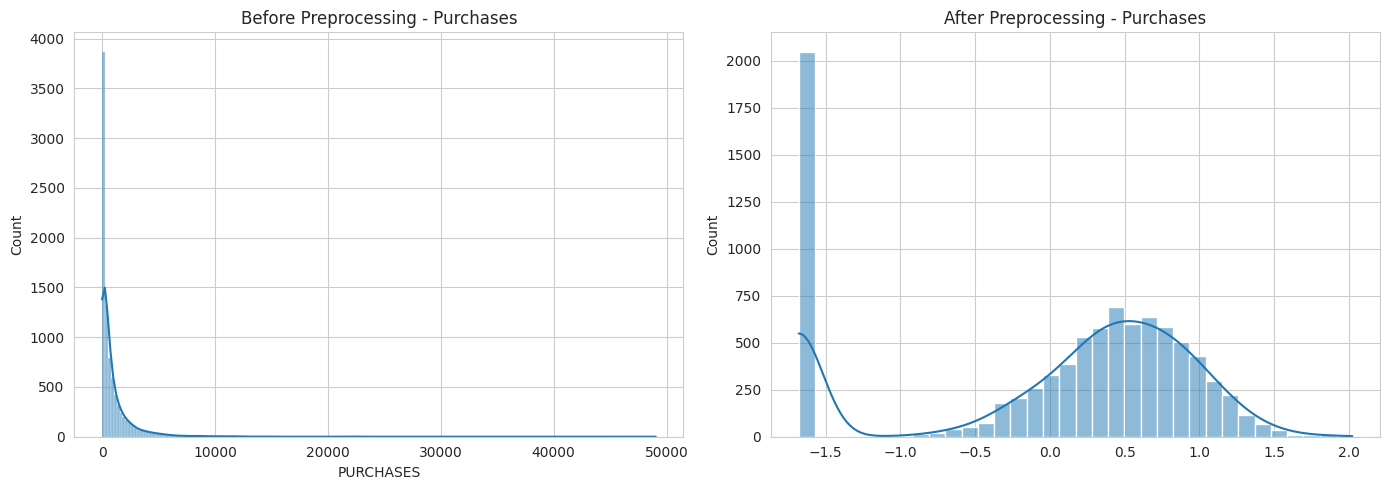

In [6]:
# Compare feature distributions before and after preprocessing

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['PURCHASES'], kde=True, ax=axes[0])
axes[0].set_title("Before Preprocessing - Purchases")

sns.histplot(X_scaled[:, data.columns.get_loc('PURCHASES')],
             kde=True, ax=axes[1])

axes[1].set_title("After Preprocessing - Purchases")

plt.tight_layout()
plt.show()

In [7]:
# Select a common sample for all algorithms

sample_size = min(4000, len(X_scaled))

rng = np.random.RandomState(RANDOM_STATE)

sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X = X_scaled[sample_indices]

print("Sample Size:", X.shape)
print("Number of Features:", X.shape[1])

Sample Size: (4000, 17)
Number of Features: 17


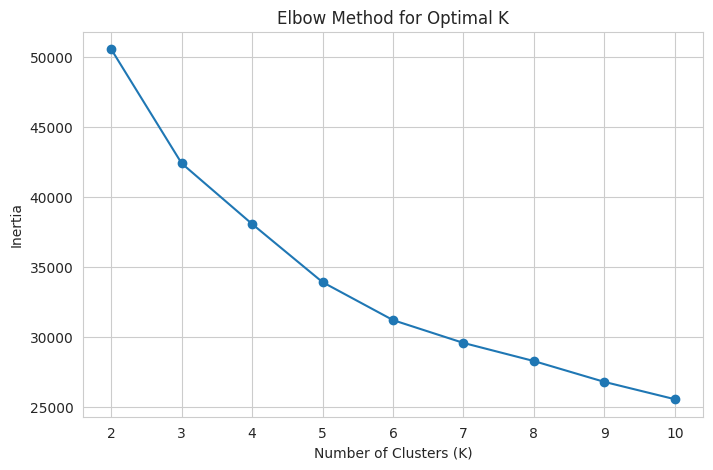

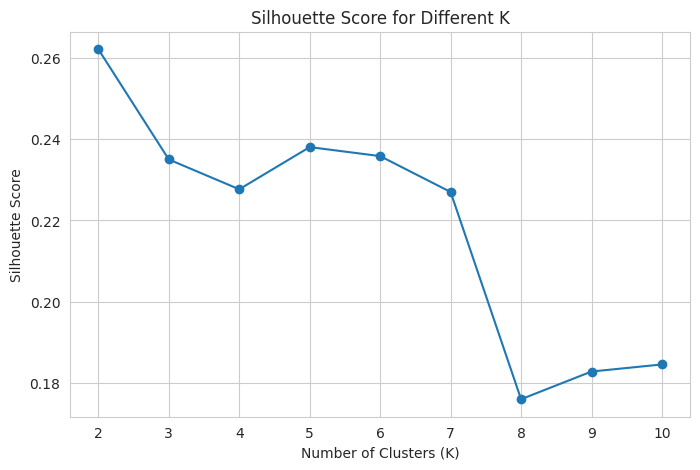

Optimal Number of Clusters: 2
Best Silhouette Score: 0.2621337625437456


In [8]:
# Elbow Method and Silhouette Score

inertia_values = []
silhouette_values = []

k_range = range(2, 11)

for k in k_range:

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertia_values.append(model.inertia_)

    score = silhouette_score(
        X,
        labels,
        sample_size=min(1500, len(X)),
        random_state=RANDOM_STATE
    )

    silhouette_values.append(score)

# Plot Elbow Method

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia_values, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_range))
plt.show()

# Plot Silhouette Scores

plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_values, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K")
plt.xticks(list(k_range))
plt.show()

# Select optimal K based on highest silhouette score

optimal_k = list(k_range)[np.argmax(silhouette_values)]

print("Optimal Number of Clusters:", optimal_k)
print("Best Silhouette Score:", max(silhouette_values))

In [9]:
# Implement K-Means using optimal K

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

print("K-Means Clustering Completed!")

print("\nCluster Distribution:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print("\nSilhouette Score:",
      round(silhouette_score(
          X, kmeans_labels,
          sample_size=min(1500, len(X)),
          random_state=RANDOM_STATE
      ), 4))

print("\nDavies-Bouldin Index:",
      round(davies_bouldin_score(X, kmeans_labels), 4))

K-Means Clustering Completed!

Cluster Distribution:
0    2676
1    1324
Name: count, dtype: int64

Silhouette Score: 0.2621

Davies-Bouldin Index: 1.4728


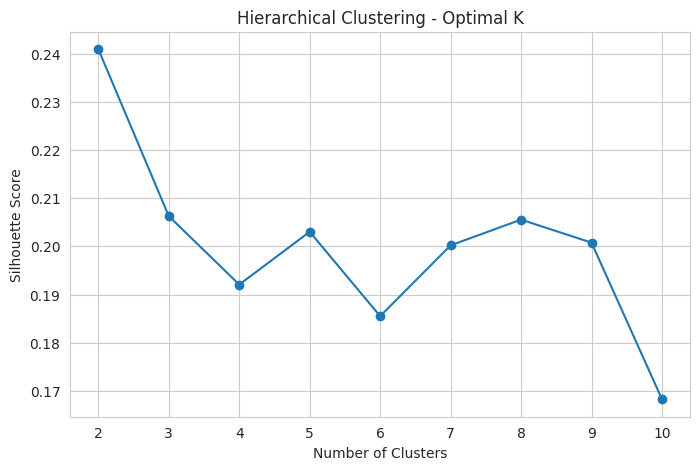

Optimal Hierarchical Clusters: 2
Best Silhouette Score: 0.241


In [10]:
# Test different cluster numbers

hierarchical_scores = []
hierarchical_db_scores = []

for k in range(2, 11):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X)

    sil = silhouette_score(
        X,
        labels,
        sample_size=min(1500, len(X)),
        random_state=RANDOM_STATE
    )

    db = davies_bouldin_score(X, labels)

    hierarchical_scores.append(sil)
    hierarchical_db_scores.append(db)


# Visualize silhouette scores

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), hierarchical_scores, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Hierarchical Clustering - Optimal K")
plt.xticks(range(2, 11))
plt.show()


# Select optimal number of clusters

hierarchical_k = np.argmax(hierarchical_scores) + 2

print("Optimal Hierarchical Clusters:", hierarchical_k)
print("Best Silhouette Score:",
      round(max(hierarchical_scores), 4))

In [11]:
# Implement Agglomerative Clustering

hierarchical = AgglomerativeClustering(
    n_clusters=hierarchical_k,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(X)

print("Hierarchical Clustering Completed!")

print("\nCluster Distribution:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

print("\nSilhouette Score:",
      round(silhouette_score(
          X, hierarchical_labels,
          sample_size=min(1500, len(X)),
          random_state=RANDOM_STATE
      ), 4))

print("\nDavies-Bouldin Index:",
      round(davies_bouldin_score(X, hierarchical_labels), 4))

Hierarchical Clustering Completed!

Cluster Distribution:
0    2839
1    1161
Name: count, dtype: int64

Silhouette Score: 0.241

Davies-Bouldin Index: 1.4928


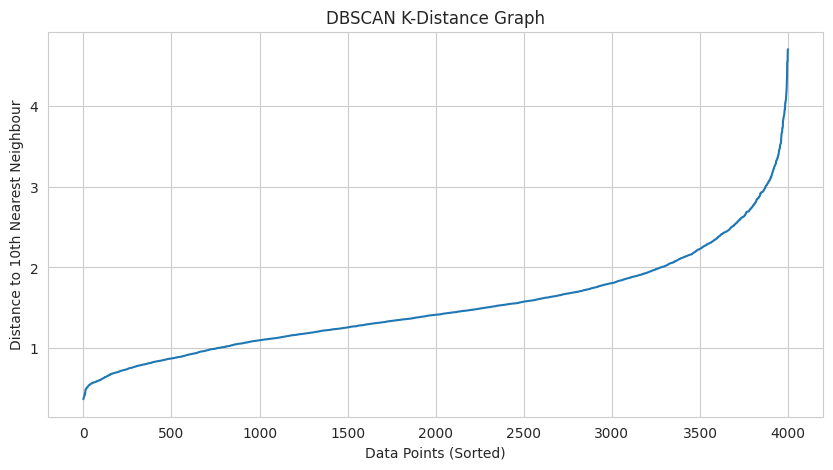

In [12]:
# Calculate nearest-neighbour distances

min_samples = 10

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X)

distances, indices = neighbors.kneighbors(X)

# Sort distances to find suitable epsilon

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Data Points (Sorted)")
plt.ylabel("Distance to 10th Nearest Neighbour")
plt.title("DBSCAN K-Distance Graph")

plt.show()

In [13]:
# Test different epsilon values using distance quantiles

eps_candidates = np.unique(
    np.quantile(
        k_distances,
        [0.90, 0.92, 0.94, 0.96, 0.98, 0.99, 0.995]
    )
)

dbscan_results = []

best_dbscan_score = -1
best_eps = None
best_labels = None

for eps in eps_candidates:

    model = DBSCAN(
        eps=float(eps),
        min_samples=min_samples
    )

    labels = model.fit_predict(X)

    # Exclude noise points for silhouette calculation

    valid_mask = labels != -1
    valid_labels = labels[valid_mask]

    n_clusters = len(set(valid_labels))
    noise_percentage = np.mean(labels == -1) * 100

    if n_clusters >= 2 and valid_mask.sum() > n_clusters:

        score = silhouette_score(
            X[valid_mask],
            valid_labels,
            sample_size=min(1500, valid_mask.sum()),
            random_state=RANDOM_STATE
        )

        db_index = davies_bouldin_score(
            X[valid_mask],
            valid_labels
        )

        dbscan_results.append({
            'Epsilon': eps,
            'Clusters': n_clusters,
            'Noise (%)': noise_percentage,
            'Silhouette Score': score,
            'Davies-Bouldin Index': db_index
        })

        # Prefer a high silhouette score with
        # a reasonable percentage of noise

        if noise_percentage < 50 and score > best_dbscan_score:

            best_dbscan_score = score
            best_eps = float(eps)
            best_labels = labels.copy()


# Display parameter comparison

dbscan_results_df = pd.DataFrame(dbscan_results)

display(dbscan_results_df.round(4))

if best_eps is None:
    raise ValueError(
        "DBSCAN did not identify at least two suitable clusters. "
        "Try adjusting eps_candidates or min_samples."
    )

print("Best Epsilon:", best_eps)
print("Minimum Samples:", min_samples)
print("Best Silhouette Score:", round(best_dbscan_score, 4))

,Epsilon,Clusters,Noise (%),Silhouette Score,Davies-Bouldin Index
0,2.3682,5,3.550,0.0858,1.1323
1,2.4999,2,2.700,0.1201,1.3016
2,2.6702,2,1.725,0.1448,1.4424


Best Epsilon: 2.6702450133885605
Minimum Samples: 10
Best Silhouette Score: 0.1448


In [14]:
# Train final DBSCAN model

dbscan = DBSCAN(
    eps=best_eps,
    min_samples=min_samples
)

dbscan_labels = dbscan.fit_predict(X)

# Cluster distribution

print("DBSCAN Clustering Completed!")

print("\nCluster Distribution:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

# Noise analysis

noise_count = np.sum(dbscan_labels == -1)

print("\nNoise Points:", noise_count)

print("Noise Percentage:",
      round(noise_count / len(dbscan_labels) * 100, 2), "%")

# Evaluate DBSCAN excluding noise

valid_mask = dbscan_labels != -1

if len(set(dbscan_labels[valid_mask])) >= 2:

    print("\nSilhouette Score:",
          round(silhouette_score(
              X[valid_mask],
              dbscan_labels[valid_mask],
              sample_size=min(1500, valid_mask.sum()),
              random_state=RANDOM_STATE
          ), 4))

    print("\nDavies-Bouldin Index:",
          round(davies_bouldin_score(
              X[valid_mask],
              dbscan_labels[valid_mask]
          ), 4))

DBSCAN Clustering Completed!

Cluster Distribution:
-1      69
 0    3905
 1      26
Name: count, dtype: int64

Noise Points: 69
Noise Percentage: 1.72 %

Silhouette Score: 0.1448

Davies-Bouldin Index: 1.4424


Explained Variance Ratio: [0.33944366 0.21828532]
Total Variance Explained: 55.77 %


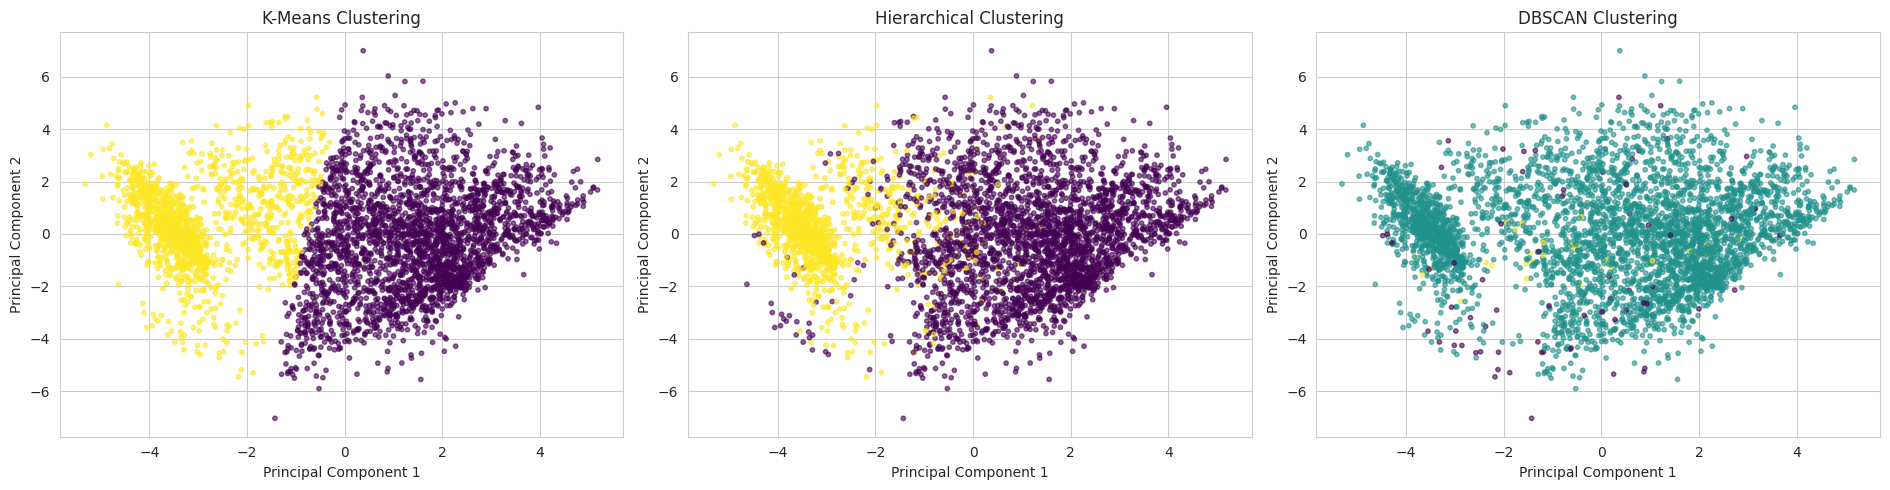

In [15]:
# Reduce data to 2 dimensions using PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("Explained Variance Ratio:",
      pca.explained_variance_ratio_)

print("Total Variance Explained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")


# Prepare labels for visualization

cluster_results = {
    'K-Means': kmeans_labels,
    'Hierarchical': hierarchical_labels,
    'DBSCAN': dbscan_labels
}

# Plot all three clustering results

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (name, labels) in zip(axes, cluster_results.items()):

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap='viridis',
        s=10,
        alpha=0.6
    )

    ax.set_title(f"{name} Clustering")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [16]:
# Calculate evaluation metrics

results = []

# K-Means

results.append({
    'Algorithm': 'K-Means',
    'Clusters': len(set(kmeans_labels)),
    'Silhouette Score': silhouette_score(
        X, kmeans_labels,
        sample_size=min(1500, len(X)),
        random_state=RANDOM_STATE
    ),
    'Davies-Bouldin Index': davies_bouldin_score(
        X, kmeans_labels
    ),
    'Noise (%)': 0
})


# Hierarchical

results.append({
    'Algorithm': 'Hierarchical',
    'Clusters': len(set(hierarchical_labels)),
    'Silhouette Score': silhouette_score(
        X, hierarchical_labels,
        sample_size=min(1500, len(X)),
        random_state=RANDOM_STATE
    ),
    'Davies-Bouldin Index': davies_bouldin_score(
        X, hierarchical_labels
    ),
    'Noise (%)': 0
})


# DBSCAN

valid_mask = dbscan_labels != -1

if len(set(dbscan_labels[valid_mask])) >= 2:

    results.append({
        'Algorithm': 'DBSCAN',
        'Clusters': len(set(dbscan_labels[valid_mask])),
        'Silhouette Score': silhouette_score(
            X[valid_mask],
            dbscan_labels[valid_mask],
            sample_size=min(1500, valid_mask.sum()),
            random_state=RANDOM_STATE
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            X[valid_mask],
            dbscan_labels[valid_mask]
        ),
        'Noise (%)': np.mean(dbscan_labels == -1) * 100
    })


# Create comparison table

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by='Silhouette Score',
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

print("Best Silhouette Score Algorithm:",
      comparison_df.iloc[0]['Algorithm'])

print("Lowest Davies-Bouldin Index Algorithm:",
      comparison_df.loc[
          comparison_df['Davies-Bouldin Index'].idxmin(),
          'Algorithm'
      ])

,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Noise (%)
0,K-Means,2,0.2621,1.4728,0.000
1,Hierarchical,2,0.2410,1.4928,0.000
2,DBSCAN,2,0.1448,1.4424,1.725


Best Silhouette Score Algorithm: K-Means
Lowest Davies-Bouldin Index Algorithm: DBSCAN


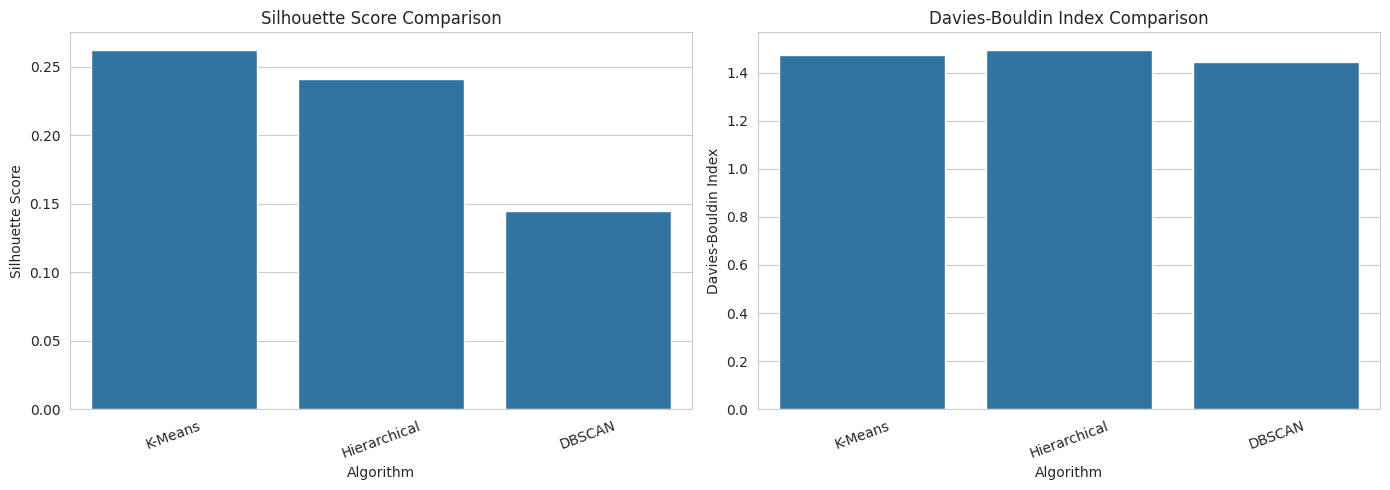

In [17]:
# Compare clustering algorithms visually

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Silhouette Score

sns.barplot(
    data=comparison_df,
    x='Algorithm',
    y='Silhouette Score',
    ax=axes[0]
)

axes[0].set_title("Silhouette Score Comparison")
axes[0].tick_params(axis='x', rotation=20)


# Davies-Bouldin Index

sns.barplot(
    data=comparison_df,
    x='Algorithm',
    y='Davies-Bouldin Index',
    ax=axes[1]
)

axes[1].set_title("Davies-Bouldin Index Comparison")
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

Customer Cluster Profiles:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,1151.79,0.87,1475.47,859.10,617.18,389.95,0.71,0.29,0.53,0.06,1.26,21.93,4579.81,1757.20,740.58,0.22,11.61
1,2311.95,0.90,109.32,85.93,23.43,2092.26,0.09,0.05,0.03,0.28,6.48,1.43,4245.52,1719.09,1036.71,0.04,11.35


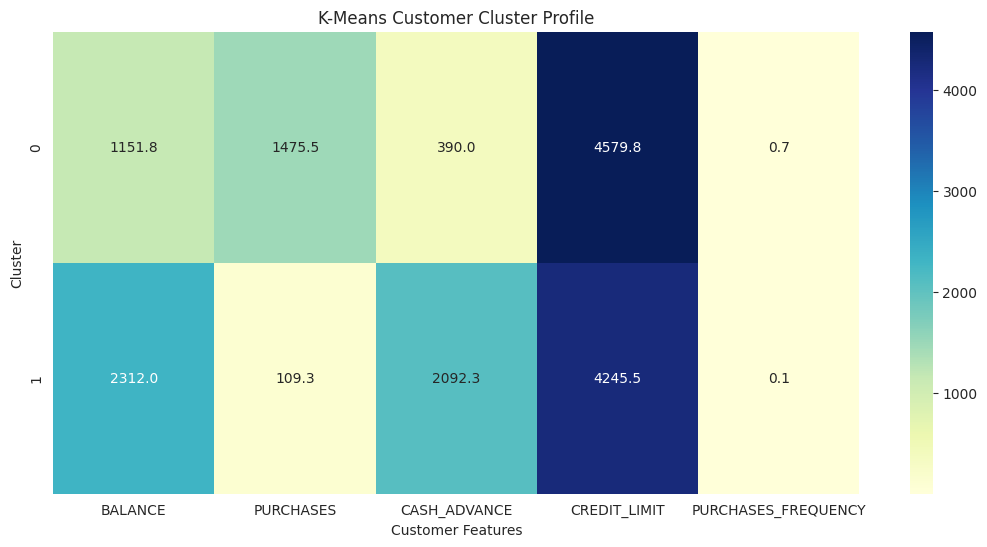

In [18]:
# Recover original feature values for sampled customers

profile_data = data_imputed.iloc[
    sample_indices
].reset_index(drop=True).copy()

# Add K-Means cluster labels

profile_data['Cluster'] = kmeans_labels

# Calculate average feature values for each cluster

cluster_profile = profile_data.groupby('Cluster').mean()

print("Customer Cluster Profiles:")

display(cluster_profile.round(2))


# Visualize important customer features

important_features = [
    'BALANCE',
    'PURCHASES',
    'CASH_ADVANCE',
    'CREDIT_LIMIT',
    'PURCHASES_FREQUENCY'
]

plt.figure(figsize=(13, 6))

sns.heatmap(
    cluster_profile[important_features],
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title("K-Means Customer Cluster Profile")
plt.xlabel("Customer Features")
plt.ylabel("Cluster")

plt.show()

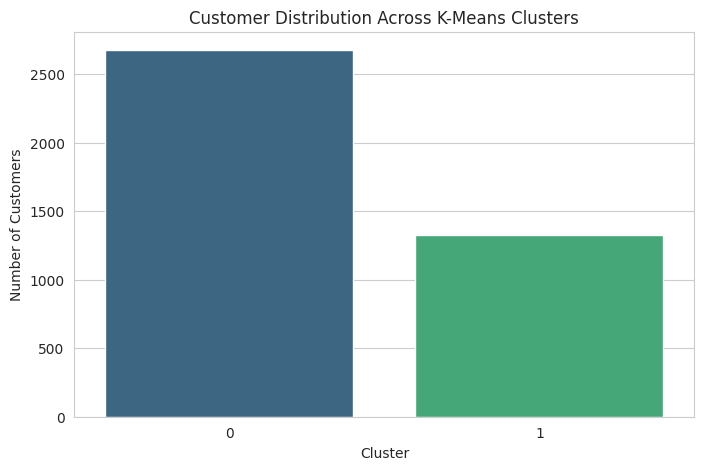

Percentage Distribution:
0    66.9
1    33.1
Name: proportion, dtype: float64


In [19]:
# Visualize customer distribution across K-Means clusters

plt.figure(figsize=(8, 5))

sns.countplot(
    x=kmeans_labels,
    hue=kmeans_labels,
    palette='viridis',
    legend=False
)

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

print("Percentage Distribution:")

print(
    (pd.Series(kmeans_labels)
     .value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

## Conclusion
The Credit Card Customer dataset was successfully analyzed using three clustering algorithms: K-Means, Agglomerative Hierarchical Clustering and DBSCAN.
- K-Means grouped customers based on similarity in their financial behaviour.
- Hierarchical clustering identified groups by repeatedly merging similar customers.
- DBSCAN identified dense customer groups and detected unusual observations as noise.
- PCA provided a two-dimensional visualization of the generated clusters.
- Silhouette Score and Davies-Bouldin Index were used to evaluate clustering quality.
The comparison of evaluation metrics helps determine which algorithm is most suitable for this customer segmentation problem. The final selection should consider cluster separation, compactness, number of clusters and DBSCAN noise percentage.

## Applications:
- Customer segmentation.
- Personalized marketing.
- Credit card usage analysis.
- Identifying high-spending and low-spending customer groups.
- Detecting unusual customer behaviour.